# 08 — Fusão: features da implementação original + Transformer AE (J1, J2)

Plano: [PLANO_JUNTAR_DEEP_LEARNING.md](../../PLANO_JUNTAR_DEEP_LEARNING.md), Fases 1–3. Regras fixadas **antes** dos
resultados em [PROTOCOLO.md](PROTOCOLO.md), seção 6.

- **Features originais** (`features_originais.py`): por célula de 320 m, as 20 features da implementação original
  (médias e desvios de B2, B3, B4, B8, B11, B12; NDVI média e desvio; GNDVI; BSI; energia de Fourier do NDVI em 4 anéis).
- **Detectores "Original"** (`baselines.py`): IForest, kNN e Deep SVDD sobre `[F, F − histórico]`, e a mudança de
  textura de Fourier. Ajustados só com células normais de treino.
- **Transformer AE**: o checkpoint já treinado (`masked`), **sem retreinar**, pontuando cada célula.
- **Fusão** (`fusao.py`): cada score vira um z-score robusto em relação aos normais de validação; o score combinado é a
  média dos z (principal). J1 combina no patch; J2 combina em cada célula e depois tira o máximo do patch.
- **Combinação principal:** AE + IForest nas features originais. As outras são ablação.

**Fonte:** `tapajos_sub` = sub-AOI, avaliação nos blocos de treino em 2023–2025 (**diagnóstico, não reportar**), como
nos notebooks 06 e 07. Com as AOIs completas, trocar `FONTE`.

In [1]:
import sys, os, json, time, glob
import numpy as np
import pandas as pd
import zarr
import config, utils, baselines, embeddings, modelo, avaliacao, fusao
import features_originais as fo
config.make_dirs()
utils.set_seed(config.SEED)

FONTE, AOI = 'tapajos_sub', 'tapajos'
EVAL_SPLIT = 'train' if FONTE.endswith('_sub') else ('test' if AOI == 'tapajos' else 'test_gen')
CKPT = config.CHECKPOINTS_DIR / f'transformer_ae_masked_{FONTE}.pt'
AE = 'Transformer AE | masked'
NDVI = 'Espectral | queda de NDVI'
KNN_TM = 'TerraMind S2S1 | kNN no delta'
PRINCIPAL = 'AE + Original IForest'
PARES = {PRINCIPAL: [AE, baselines.ORIG_IFOREST],          # combinação principal (PROTOCOLO, seção 6)
         'AE + queda de NDVI': [AE, NDVI],
         'AE + Fourier': [AE, baselines.ORIG_FOURIER],
         'AE + kNN no delta TerraMind': [AE, KNN_TM]}
print('avaliação em', EVAL_SPLIT, '(DIAGNÓSTICO, não reportar)' if EVAL_SPLIT == 'train' else '')
run_dir = utils.new_run(f'etapa_fusao_{FONTE}')

avaliação em train (DIAGNÓSTICO, não reportar)


## 1. Features originais nas células (Fase 1)

Na sub-AOI, calculadas a partir do cubo de pixels (`fo.orig_from_cube`). Nas AOIs completas, o `stream_embeddings.py` já grava `orig_cells` na mesma passada.

In [2]:
emb_path = config.EMBEDDINGS_DIR / f'{FONTE}.npz'
cz = zarr.open_group(str(embeddings.cells_path(emb_path)), mode='r')
if 'orig_cells' not in cz or not all(cz.attrs.get('orig_done', [False])):
    t0 = time.time()
    fo.orig_from_cube(config.CUBE_DIR / config.CUBE_PATH_NAME, emb_path)
    print(f'orig_cells calculado em {(time.time() - t0) / 60:.1f} min')
    cz = zarr.open_group(str(embeddings.cells_path(emb_path)), mode='r')
oc = cz['orig_cells']
print('orig_cells', oc.shape, '| features:', list(cz.attrs['orig_names']))
amostra = oc[::16, ::4].astype(np.float32).reshape(-1, oc.shape[-1])
print(f'células sem dado (< 50% limpas): {np.isnan(amostra).any(1).mean():.1%} (amostra)')
pd.DataFrame(amostra, columns=cz.attrs['orig_names']).describe().T[['mean', 'std', 'min', 'max']].round(4)

orig_cells (256, 28, 49, 13) | features: ['B2_desvio', 'B3_desvio', 'B4_desvio', 'B8_desvio', 'B11_desvio', 'B12_desvio', 'NDVI_desvio', 'GNDVI_media', 'BSI_media', 'FFT_NDVI_anel1', 'FFT_NDVI_anel2', 'FFT_NDVI_anel3', 'FFT_NDVI_anel4']
células sem dado (< 50% limpas): 2.1% (amostra)


,mean,std,min,max
B2_desvio,0.0122,0.0076,0.0018,0.0935
B3_desvio,0.0139,0.0084,0.0031,0.0894
B4_desvio,0.0145,0.0116,0.0018,0.1298
B8_desvio,0.0451,0.0140,0.0092,0.1481
B11_desvio,0.0224,0.0107,0.0038,0.0857
B12_desvio,0.0138,0.0076,0.0021,0.0754
NDVI_desvio,0.0709,0.0488,0.0108,0.3887
GNDVI_media,0.6369,0.0781,0.2416,0.7812
BSI_media,-0.2374,0.0589,-0.3728,0.1214
FFT_NDVI_anel1,-1.0524,0.6906,-3.6660,1.0703


## 2. Detectores com as features originais (Fase 2)

Mesmo código e mesmas amostras do `06_baselines` (histórico de 4 trimestres). Só TerraMind S2 + S1, para o par de controle. Guardamos os scores por célula dos métodos que entram na fusão.

In [3]:
KEEP = [baselines.ORIG_IFOREST, baselines.ORIG_FOURIER, NDVI, KNN_TM]
s4, ctx4, lab = baselines.load(FONTE, AOI)
t0 = time.time()
base, cells_b, info = baselines.run_all(s4, ctx4, cfgs=('s2s1',), keep_cells=KEEP)
print(f'baselines: {(time.time() - t0) / 60:.1f} min')
pd.concat([s4[['patch_id', 'step']], base], axis=1).to_csv(run_dir / 'scores_baselines.csv.gz', index=False)

células de ajuste: treino 39996, val 8232 (0.1 min)


ajuste feito (0.8 min); pontuando


  1536/6143 amostras  1.6 min


C:\Users\gabri\Documents\ProjetoGrassQuality\notebooks\gabriel\baselines.py:286: RuntimeWarning: All-NaN slice encountered
  agg[name] = np.nanmax(v, axis=1) if not np.isnan(v).all() else np.full(n, np.nan)
C:\Users\gabri\Documents\ProjetoGrassQuality\notebooks\gabriel\baselines.py:287: RuntimeWarning: Mean of empty slice
  agg[f'{name} [média]'] = np.nanmean(v, axis=1)


  3072/6143 amostras  4.1 min


C:\Users\gabri\Documents\ProjetoGrassQuality\notebooks\gabriel\baselines.py:286: RuntimeWarning: All-NaN slice encountered
  agg[name] = np.nanmax(v, axis=1) if not np.isnan(v).all() else np.full(n, np.nan)
C:\Users\gabri\Documents\ProjetoGrassQuality\notebooks\gabriel\baselines.py:287: RuntimeWarning: Mean of empty slice
  agg[f'{name} [média]'] = np.nanmean(v, axis=1)


  4607/6143 amostras  5.0 min


C:\Users\gabri\Documents\ProjetoGrassQuality\notebooks\gabriel\baselines.py:286: RuntimeWarning: All-NaN slice encountered
  agg[name] = np.nanmax(v, axis=1) if not np.isnan(v).all() else np.full(n, np.nan)
C:\Users\gabri\Documents\ProjetoGrassQuality\notebooks\gabriel\baselines.py:287: RuntimeWarning: Mean of empty slice
  agg[f'{name} [média]'] = np.nanmean(v, axis=1)


  6143/6143 amostras  6.7 min


C:\Users\gabri\Documents\ProjetoGrassQuality\notebooks\gabriel\baselines.py:286: RuntimeWarning: All-NaN slice encountered
  agg[name] = np.nanmax(v, axis=1) if not np.isnan(v).all() else np.full(n, np.nan)
C:\Users\gabri\Documents\ProjetoGrassQuality\notebooks\gabriel\baselines.py:287: RuntimeWarning: Mean of empty slice
  agg[f'{name} [média]'] = np.nanmean(v, axis=1)


baselines: 7.4 min


## 3. Transformer AE por célula (checkpoint, sem retreinar)

Conferência: o máximo das células tem de bater com o score salvo pelo `07_transformer_ae`.

In [4]:
s8, ctx8, _ = baselines.load(FONTE, AOI, k=modelo.K_SEQ)
ae = modelo.Trainer.load(CKPT)
t0 = time.time()
err = modelo.score_all(ae, s8, ctx8, log=False)
print(f'AE: {len(err)} amostras x 49 células em {(time.time() - t0) / 60:.1f} min')

salvo = pd.read_csv(sorted(glob.glob(str(config.RESULTS_DIR / f'etapa6_transformer_ae_{FONTE}' / '*' / 'scores_trimestrais.csv.gz')))[-1])
chk = s8.loc[err.index, ['patch_id', 'step']].assign(novo=err.max(1).values).merge(salvo[['patch_id', 'step', AE]], on=['patch_id', 'step'])
print('máx. diferença para o score salvo:', float((chk['novo'] - chk[AE]).abs().max()))

AE: 5120 amostras x 49 células em 0.8 min
máx. diferença para o score salvo: 2.2302246094341172e-07


C:\Users\gabri\AppData\Local\Temp\ipykernel_27012\1520968952.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  chk = s8.loc[err.index, ['patch_id', 'step']].assign(novo=err.max(1).values).merge(salvo[['patch_id', 'step', AE]], on=['patch_id', 'step'])


## 4. Alinhar as duas tabelas

O AE só pontua amostras com 8 trimestres de histórico; os baselines, com 4. A comparação usa só as amostras que têm os dois, como no `07`. A referência da fusão são as amostras `val_normal` (T ≤ 2022).

In [5]:
key = lambda s, idx: pd.MultiIndex.from_frame(s.loc[idx, ['patch_id', 'step']])
ae_cells = pd.DataFrame(err.values, index=key(s8, err.index))
b_cells = {m: pd.DataFrame(v.values, index=key(s4, v.index)) for m, v in cells_b.items()}
b_patch = base.set_axis(key(s4, base.index))
comum = ae_cells.index.intersection(b_patch.index)
meta = s8.set_index(['patch_id', 'step']).loc[comum]
cells_all = {AE: ae_cells.loc[comum], **{m: v.loc[comum] for m, v in b_cells.items()}}
ref = meta['val_normal'].values
print(f'amostras em comum: {len(comum)} | referência val_normal: {ref.sum()} amostras ({ref.sum() * 49} células)')
print('cobertura das amostras de referência:', meta.loc[ref, 'cobertura'].value_counts().to_dict())

amostras em comum: 5120 | referência val_normal: 116 amostras (5684 células)
cobertura das amostras de referência: {'floresta': 116}


## 5. J1 — fusão no patch

Combina os scores de patch já agregados (máximo das células de cada método).

In [6]:
patch = pd.DataFrame({AE: cells_all[AE].max(1).values}, index=comum).join(b_patch.loc[comum, KEEP])
j1 = pd.concat([fusao.fuse_patch(patch, ms, ref, f'Fusão J1 | {nome}') for nome, ms in PARES.items()], axis=1)
j1.describe().T[['mean', '50%', 'max']].round(2)

C:\Users\gabri\AppData\Local\Temp\ipykernel_27012\1704215358.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  patch = pd.DataFrame({AE: cells_all[AE].max(1).values}, index=comum).join(b_patch.loc[comum, KEEP])


,mean,50%,max
Fusão J1 | AE + Original IForest [z_media],0.92,0.90,4.42
Fusão J1 | AE + Original IForest [p_media],0.72,0.82,1.00
Fusão J1 | AE + Original IForest [p_max],0.80,0.91,1.00
Fusão J1 | AE + queda de NDVI [z_media],0.67,0.51,5.31
Fusão J1 | AE + queda de NDVI [p_media],0.64,0.69,1.00
Fusão J1 | AE + queda de NDVI [p_max],0.75,0.85,1.00
Fusão J1 | AE + Fourier [z_media],1.59,0.95,40.91
Fusão J1 | AE + Fourier [p_media],0.69,0.78,1.00
Fusão J1 | AE + Fourier [p_max],0.78,0.90,1.00
Fusão J1 | AE + kNN no delta TerraMind [z_media],0.72,0.59,5.68


## 6. J2 — fusão na célula

Combina os z-scores em cada uma das 49 células e só então tira o máximo do patch: o evento precisa aparecer na mesma célula nos dois sinais.

In [7]:
j2 = pd.concat([fusao.fuse_cells(cells_all, ms, ref, f'Fusão J2 | {nome}') for nome, ms in PARES.items()], axis=1)
j2.describe().T[['mean', '50%', 'max']].round(2).head(8)

,mean,50%,max
Fusão J2 | AE + Original IForest [z_media],3.93,3.86,16.01
Fusão J2 | AE + Original IForest [z_media] [média],1.06,0.81,5.74
Fusão J2 | AE + Original IForest [p_media],0.94,0.98,1.00
Fusão J2 | AE + Original IForest [p_media] [média],0.66,0.69,1.00
Fusão J2 | AE + Original IForest [p_max],0.98,1.00,1.00
Fusão J2 | AE + Original IForest [p_max] [média],0.77,0.80,1.00
Fusão J2 | AE + queda de NDVI [z_media],2.69,2.34,12.50
Fusão J2 | AE + queda de NDVI [z_media] [média],0.62,0.48,5.71


## 7. Avaliação

Mesmo protocolo dos notebooks 06 e 07 (`avaliacao.evaluate`, IC por bootstrap de blocos), trimestral e anual (máximo dos trimestres do ano).

In [8]:
extra = [c for c in b_patch.columns if c not in KEEP]
tab = pd.concat([patch, b_patch.loc[comum, extra], j1, j2], axis=1).reset_index()
tab.to_csv(run_dir / 'scores_trimestrais.csv.gz', index=False)

def eval_all(score_df, labels, k):
    out = []
    for col in [c for c in score_df.columns if '|' in c]:
        sc = score_df[['patch_id', k]].assign(score=score_df[col].values).dropna(subset=['score'])
        out.append(avaliacao.evaluate(sc, labels, lab['grade'], key=k, split=EVAL_SPLIT, n_boot=200).assign(metodo=col))
    return pd.concat(out, ignore_index=True)

res_q = eval_all(tab, lab['trim'], 'step').assign(resolucao='trimestral')
anual = tab.assign(year=tab['step'].str[:4].astype(int)).drop(columns='step').groupby(['patch_id', 'year']).max().reset_index()
res_a = eval_all(anual, lab['anual'], 'year').assign(resolucao='anual')
res = pd.concat([res_q, res_a], ignore_index=True)
res['agregacao'] = np.where(res['metodo'].str.endswith('[média]'), 'média', 'máximo')
res['metodo'] = res['metodo'].str.replace(' [média]', '', regex=False)
res.to_csv(run_dir / 'metricas.csv', index=False)

cols = ['AUROC', 'AUROC_lo', 'AUROC_hi', 'AUPRC', 'TPR@1%FPR', 'n_pos']
main = res[(res['agregacao'] == 'máximo') & (res['tarefa'] == 'todos')]
for resol in ['trimestral', 'anual']:
    t = main[main['resolucao'] == resol].set_index('metodo')[cols].sort_values('AUROC', ascending=False)
    print(f'== {resol}, todas as anomalias ({EVAL_SPLIT}, 2023–2025)'); display(t.round(3))

== trimestral, todas as anomalias (train, 2023–2025)


,AUROC,AUROC_lo,AUROC_hi,AUPRC,TPR@1%FPR,n_pos
metodo,,,,,,
Original | Deep SVDD (20 features + delta),0.737,0.675,0.815,0.206,0.084,166
Fusão J2 | AE + kNN no delta TerraMind [p_max],0.735,0.652,0.813,0.181,0.000,166
Fusão J1 | AE + kNN no delta TerraMind [p_max],0.733,0.649,0.812,0.180,0.000,166
TerraMind S2S1 | kNN no delta,0.733,0.630,0.822,0.223,0.090,166
Fusão J1 | AE + kNN no delta TerraMind [p_media],0.726,0.634,0.811,0.171,0.024,166
Fusão J2 | AE + kNN no delta TerraMind [p_media],0.726,0.630,0.812,0.174,0.024,166
Fusão J1 | AE + Fourier [p_max],0.723,0.641,0.812,0.153,0.000,166
Fusão J1 | AE + queda de NDVI [p_media],0.722,0.628,0.811,0.170,0.024,166
Fusão J2 | AE + queda de NDVI [p_media],0.721,0.619,0.814,0.176,0.024,166


== anual, todas as anomalias (train, 2023–2025)


,AUROC,AUROC_lo,AUROC_hi,AUPRC,TPR@1%FPR,n_pos
metodo,,,,,,
Original | kNN (20 features + delta),0.972,0.932,0.990,0.984,0.657,268
TerraMind S2S1 | kNN estático (sem tempo),0.969,0.931,0.990,0.982,0.627,268
Original | Deep SVDD (20 features + delta),0.950,0.923,0.973,0.972,0.549,268
Original | IForest (20 features + delta),0.931,0.887,0.962,0.960,0.429,268
TerraMind S2S1 | Deep SVDD no delta,0.926,0.885,0.957,0.960,0.295,268
Fusão J1 | AE + Original IForest [p_media],0.900,0.855,0.940,0.922,0.123,268
TerraMind S2S1 | kNN no delta,0.899,0.857,0.937,0.943,0.347,268
Fusão J2 | AE + Fourier [z_media],0.884,0.805,0.941,0.937,0.343,268
Fusão J1 | AE + Fourier [z_media],0.882,0.811,0.929,0.932,0.313,268


In [9]:
print('== AUROC por tipo, trimestral (máximo das células)')
sel = [AE, baselines.ORIG_IFOREST, NDVI, baselines.ORIG_FOURIER, KNN_TM] + \
      [f'Fusão J2 | {p} [{r}]' for p in PARES for r in fusao.RULES] + [f'Fusão J1 | {PRINCIPAL} [z_media]']
q = res[(res['agregacao'] == 'máximo') & (res['resolucao'] == 'trimestral') & res['metodo'].isin(sel)]
display(q.pivot(index='metodo', columns='tarefa', values='AUROC').reindex(sel).round(3))

== AUROC por tipo, trimestral (máximo das células)


tarefa,degradacao,desmatamento,fogo,mineracao,todos
metodo,,,,,
Transformer AE | masked,0.704,0.815,0.677,0.658,0.684
Original | IForest (20 features + delta),0.721,0.744,0.669,0.736,0.699
Espectral | queda de NDVI,0.765,0.764,0.758,0.601,0.714
Original | mudança de textura (Fourier),0.770,0.676,0.640,0.789,0.687
TerraMind S2S1 | kNN no delta,0.716,0.891,0.729,0.693,0.733
Fusão J2 | AE + Original IForest [z_media],0.745,0.802,0.687,0.728,0.707
Fusão J2 | AE + Original IForest [p_media],0.727,0.762,0.675,0.742,0.702
Fusão J2 | AE + Original IForest [p_max],0.739,0.808,0.690,0.709,0.704
Fusão J2 | AE + queda de NDVI [z_media],0.708,0.827,0.740,0.654,0.720


### Comparação pareada (mesmos blocos sorteados para os dois métodos)

Diferença de AUROC/AUPRC da combinação principal (J2, regra principal) contra cada parte e contra o melhor sinal simples.

In [10]:
PRINC_COL = f'Fusão J2 | {PRINCIPAL} [z_media]'
def sc(col):
    return tab[['patch_id', 'step']].assign(score=tab[col].values)
comp = []
for contra in [AE, baselines.ORIG_IFOREST, NDVI, KNN_TM]:
    comp.append(avaliacao.compare(sc(PRINC_COL), sc(contra), lab['trim'], lab['grade'], split=EVAL_SPLIT, n_boot=300)
                .assign(contra=contra))
comp = pd.concat(comp, ignore_index=True)
comp.to_csv(run_dir / 'comparacao_pareada.csv', index=False)
display(comp[comp['tarefa'].isin(['todos', 'desmatamento', 'fogo', 'degradacao', 'mineracao'])]
        .set_index(['contra', 'tarefa'])[['n_pos', 'dAUROC', 'dAUROC_lo', 'dAUROC_hi', 'dAUPRC']].round(3))

n_pos  dAUROC  \
contra                                   tarefa                        
Transformer AE | masked                  todos           166   0.023   
                                         desmatamento     28  -0.013   
                                         mineracao        34   0.070   
                                         fogo            102   0.010   
                                         degradacao       19   0.041   
Original | IForest (20 features + delta) todos           166   0.008   
                                         desmatamento     28   0.058   
                                         mineracao        34  -0.008   
                                         fogo            102   0.018   
                                         degradacao       19   0.024   
Espectral | queda de NDVI                todos           166  -0.007   
                                         desmatamento     28   0.037   
                                         mineracao        34   0.127   
                                         fogo            102  -0.070   
                                         degradacao       19  -0.020   
TerraMind S2S1 | kNN no delta            todos           166  -0.026   
                                         desmatamento     28  -0.089   
                                         mineracao        34   0.034   
                                         fogo            102  -0.042   
                                         degradacao       19   0.029   

                                                       dAUROC_lo  dAUROC_hi  \
contra                                   tarefa                               
Transformer AE | masked                  todos            -0.001      0.054   
                                         desmatamento     -0.045      0.011   
                                         mineracao         0.042      0.102   
                                         fogo             -0.021      0.047   
                                         degradacao        0.005      0.119   
Original | IForest (20 features + delta) todos            -0.027      0.029   
                                         desmatamento     -0.028      0.132   
                                         mineracao        -0.080      0.057   
                                         fogo             -0.026      0.042   
                                         degradacao       -0.083      0.091   
Espectral | queda de NDVI                todos            -0.076      0.067   
                                         desmatamento     -0.000      0.098   
                                         mineracao        -0.009      0.256   
                                         fogo             -0.132     -0.003   
                                         degradacao       -0.065      0.039   
TerraMind S2S1 | kNN no delta            todos            -0.072      0.018   
                                         desmatamento     -0.171      0.002   
                                         mineracao        -0.051      0.129   
                                         fogo             -0.088     -0.003   
                                         degradacao       -0.034      0.175   

                                                       dAUPRC  
contra                                   tarefa                
Transformer AE | masked                  todos         -0.001  
                                         desmatamento  -0.013  
                                         mineracao      0.005  
                                         fogo          -0.004  
                                         degradacao    -0.003  
Original | IForest (20 features + delta) todos         -0.005  
                                         desmatamento   0.014  
                                         mineracao     -0.004  
                                         fogo          -0.003  
                           

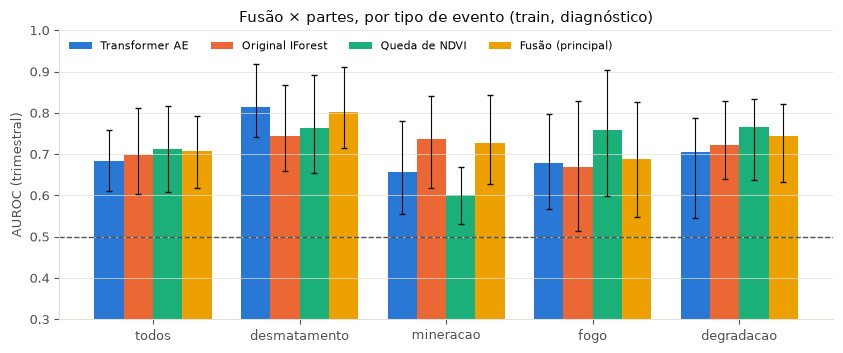

In [11]:
import matplotlib.pyplot as plt
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False})
tipos = [t for t in ['todos', 'desmatamento', 'mineracao', 'fogo', 'degradacao'] if t in set(q['tarefa'])]
mets = {AE: 'Transformer AE', baselines.ORIG_IFOREST: 'Original IForest', NDVI: 'Queda de NDVI', PRINC_COL: 'Fusão (principal)'}
pv = q.pivot(index='metodo', columns='tarefa', values='AUROC')
lo = q.pivot(index='metodo', columns='tarefa', values='AUROC_lo'); hi = q.pivot(index='metodo', columns='tarefa', values='AUROC_hi')
fig, ax = plt.subplots(figsize=(8.5, 3.6))
w = 0.2
for i, (m, rot) in enumerate(mets.items()):
    x = np.arange(len(tipos)) + (i - 1.5) * w
    v = pv.loc[m, tipos].values
    ax.bar(x, v, w, color=CAT[i], label=rot)
    ax.errorbar(x, v, yerr=[v - lo.loc[m, tipos].values, hi.loc[m, tipos].values - v], fmt='none', ecolor=INK, lw=0.8, capsize=2)
ax.axhline(0.5, color=MUTED, ls='--', lw=1)
ax.set_xticks(np.arange(len(tipos)), tipos); ax.set_ylim(0.3, 1); ax.set_ylabel('AUROC (trimestral)')
ax.grid(axis='y', color=GRID, lw=0.5); ax.legend(frameon=False, fontsize=8, ncol=4, loc='upper left')
ax.set_title(f'Fusão × partes, por tipo de evento ({EVAL_SPLIT}, diagnóstico)', color=INK)
fig.tight_layout(); fig.savefig(run_dir / 'auroc_por_tipo.png', dpi=130); plt.show()

In [12]:
resumo = {
    'fonte': FONTE, 'eval_split': EVAL_SPLIT, 'checkpoint': str(CKPT), 'principal': PRINC_COL,
    'n_amostras': int(len(comum)), 'n_ref_val_normal': int(ref.sum()),
    'auroc_todos': {r: main[main['resolucao'] == r].set_index('metodo')['AUROC'].round(4).to_dict() for r in ['trimestral', 'anual']},
    'pareado_vs': comp[comp['tarefa'] == 'todos'].set_index('contra')[['dAUROC', 'dAUROC_lo', 'dAUROC_hi']].round(4).to_dict('index'),
    'svdd_original_epocas': len(info.get('svdd_original', [])),
}
(run_dir / 'resumo.json').write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding='utf-8')
print('salvo em', run_dir)

salvo em C:\Users\gabri\Documents\ProjetoGrassQuality\results\etapa_fusao_tapajos_sub\20261104-204250


## Leitura (04/11, diagnóstico na sub-AOI — não reportar)

Run: `results/etapa_fusao_tapajos_sub/20261104-204250`. Avaliação no split `train`, 2023–2025, 166 patch-trimestres com evento.

- **Combinação principal (J2, AE + Original IForest, média dos z):** AUROC 0,707 × 0,684 do AE sozinho
  (+0,023, IC pareado −0,001 a +0,054: no limite). O ganho vem de **mineração** (+0,07, IC 0,04 a 0,10) e
  **degradação** (+0,04, IC 0,005 a 0,12). Em desmatamento o AE já era bom e fica igual. AUPRC não melhora.
- **A fusão não supera os melhores métodos sozinhos:** kNN no delta TerraMind 0,733 e **Original Deep SVDD 0,737**
  (melhor resultado trimestral até agora; desmatamento 0,886). Contra a queda de NDVI, a fusão perde em fogo (−0,07).
- **As features originais têm sinal próprio:** com o mesmo detector, IForest original 0,699 × IForest espectral
  atual 0,706 (empate), mas Deep SVDD original 0,737 × Deep SVDD TerraMind 0,686. **Fourier** é o melhor método
  em mineração (0,789), repetindo o notebook 07.
- **J1 × J2:** quase iguais; combinar na célula não ajudou nesta amostra.
- **Regras:** média dos z (principal) e média dos percentis dão resultados parecidos; o máximo dos percentis
  zera o TPR@1% FPR (empates em 1, como previsto no protocolo).
- **Anual:** kNN nas features originais 0,972 ≈ kNN estático TerraMind 0,969. Mesmo alerta "é fronteira?".
- **Limites:** sub-AOI escolhida pelos rótulos; a referência da fusão tem só 116 amostras normais de validação, todas
  floresta; ICs largos. O teste de verdade precisa das AOIs completas (Fase 5).

**Próximo passo sugerido:** manter a combinação principal registrada e incluir no caminho B (Fase 4) o AE treinado
só nas features originais (AE-ORIG), já que o Deep SVDD original foi o melhor detector.